<a href="https://colab.research.google.com/github/joearriaga6/Sales-Analytics-Projcet/blob/main/Sales_Analytics_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Import the Libraries and Upload the Data

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sqlite3

In [ ]:
from google.colab import files
uploaded = files.upload()
filename = next(iter(uploaded))
# Try reading with latin1 encoding to handle special characters
df = pd.read_csv(filename, encoding='latin1')

Saving Sample_-_Superstore[1].csv to Sample_-_Superstore[1].csv


In [ ]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

Dataset shape: (9994, 21)

Column names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']


In [ ]:
display(df.head())

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


# Inspect and Clean the Data

In [ ]:
# Standardize column names
df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

In [ ]:
# Find any missing values
print("Missing values:")
print(df.isnull().sum().sort_values(ascending=False).head(15))

Missing values:
row_id           0
order_id         0
order_date       0
ship_date        0
ship_mode        0
customer_id      0
customer_name    0
segment          0
country          0
city             0
state            0
postal_code      0
region           0
product_id       0
category         0
dtype: int64


In [ ]:
#Find any duplicate rows
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [ ]:
# Convert dates and numeric columns
df["order_date"] = pd.to_datetime(
    df["order_date"], errors="coerce"
)

df["ship_date"] = pd.to_datetime(
    df["ship_date"], errors="coerce"
)

for col in ["sales", "profit", "discount", "quantity"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

In [ ]:
# Check critical fields
df = df.dropna(
    subset=["order_date", "sales", "profit", "order_id"]
).copy()

In [ ]:
# check the cleaned data set
print("Cleaned dataset shape:", df.shape)
print(df.dtypes)

Cleaned dataset shape: (9994, 21)
row_id                    int64
order_id                 object
order_date       datetime64[ns]
ship_date        datetime64[ns]
ship_mode                object
customer_id              object
customer_name            object
segment                  object
country                  object
city                     object
state                    object
postal_code               int64
region                   object
product_id               object
category                 object
sub_category             object
product_name             object
sales                   float64
quantity                  int64
discount                float64
profit                  float64
dtype: object


# Perform Expoloratory Analysis Using Python

In [ ]:
# Finding what years are available in the dataset
df["year"] = df["order_date"].dt.year

year_summary = df.groupby("year").agg(
    first_order=("order_date", "min"),
    last_order=("order_date", "max"),
    sales=("sales", "sum"),
    profit=("profit", "sum"),
    order_count=("order_id", "nunique")
).reset_index()

print(year_summary.to_string(index=False))

 year first_order last_order       sales     profit  order_count
 2014  2014-01-03 2014-12-31 484247.4981 49543.9741          969
 2015  2015-01-02 2015-12-31 470532.5090 61618.6037         1038
 2016  2016-01-02 2016-12-31 609205.5980 81795.1743         1315
 2017  2017-01-01 2017-12-30 733215.2552 93439.2696         1687


In [ ]:
ANALYSIS_YEAR = 2017

In [ ]:
year_df = df[
    df["order_date"].dt.year == ANALYSIS_YEAR
].copy()

In [ ]:
months_present = year_df["order_date"].dt.month.nunique()

In [ ]:
print("Analysis year:", ANALYSIS_YEAR)
print("Rows:", len(year_df))
print("Months present:", months_present)
print("Date range:",
      year_df["order_date"].min(),
      "to",
      year_df["order_date"].max())

Analysis year: 2017
Rows: 3312
Months present: 12
Date range: 2017-01-01 00:00:00 to 2017-12-30 00:00:00


In [ ]:
if months_present != 12:
    print("WARNING: Verify that this year covers all 12 months.")

In [ ]:
# Measure monthly sales and profit
monthly = (
    year_df.groupby(year_df["order_date"].dt.month)
    .agg(
        sales=("sales", "sum"),
        profit=("profit", "sum"),
        orders=("order_id", "nunique"),
        units=("quantity", "sum")
    )
    .reindex(range(1, 13), fill_value=0)
)

In [ ]:
monthly.index.name = "month"
monthly["profit_margin"] = (
    monthly["profit"] / monthly["sales"].replace(0, np.nan)
)

In [ ]:
monthly["sales_mom_pct"] = (
    monthly["sales"].pct_change() * 100
)

In [ ]:
monthly["sales_3m_avg"] = monthly["sales"].rolling(
    window=3, min_periods=3
).mean()

In [ ]:
print(monthly.round(2))

           sales    profit  orders  units  profit_margin  sales_mom_pct  \
month                                                                     
1       43971.37   7140.44      69    597           0.16            NaN   
2       20301.13   1613.87      53    363           0.08         -53.83   
3       58872.35  14751.89     118    885           0.25         190.00   
4       36521.54    933.29     116    733           0.03         -37.96   
5       44261.11   6342.58     118    887           0.14          21.19   
6       52981.73   8223.34     133    931           0.16          19.70   
7       45264.42   6952.62     111    840           0.15         -14.57   
8       63120.89   9040.96     111    884           0.14          39.45   
9       87866.65  10991.56     226   1660           0.13          39.20   
10      77776.92   9275.28     147   1133           0.12         -11.48   
11     118447.82   9690.10     261   1840           0.08          52.29   
12      83829.32   8483.3

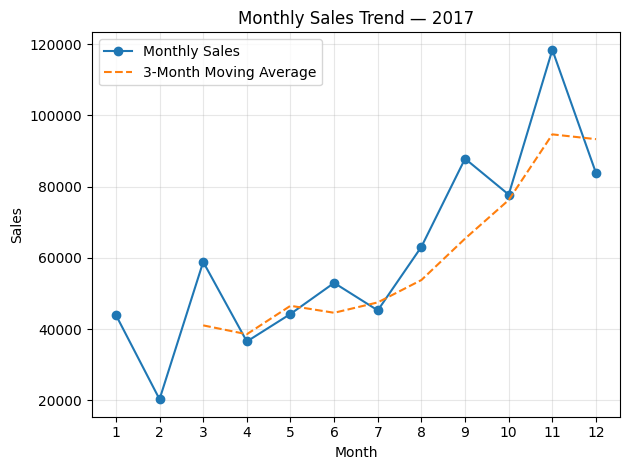

In [ ]:
# Visual to analyze trends in monthly sales
plt.plot(
    monthly.index,
    monthly["sales"],
    marker="o",
    label="Monthly Sales"
)
plt.plot(
    monthly.index,
    monthly["sales_3m_avg"],
    linestyle="--",
    label="3-Month Moving Average"
)
plt.title(f"Monthly Sales Trend — {ANALYSIS_YEAR}")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.xticks(range(1, 13))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Find each product with low profitability
subcategory = (
    year_df.groupby(["category", "sub_category"])
    .agg(
        sales=("sales", "sum"),
        profit=("profit", "sum"),
        units=("quantity", "sum"),
        orders=("order_id", "nunique"),
        avg_discount=("discount", "mean")
    )
    .reset_index()
)

In [ ]:
subcategory["profit_margin"] = (
    subcategory["profit"] /
    subcategory["sales"].replace(0, np.nan)
)


In [ ]:
print(
    subcategory.sort_values("profit").head(15)
    .round(3).to_string(index=False)
)

       category sub_category      sales    profit  units  orders  avg_discount  profit_margin
      Furniture       Tables  60893.542 -8140.695    390     100         0.265         -0.134
     Technology     Machines  43544.675 -2869.216    121      32         0.300         -0.066
Office Supplies     Supplies  16049.410  -955.313    192      59         0.071         -0.060
      Furniture    Bookcases  30024.280  -583.626    276      76         0.215         -0.019
Office Supplies    Fasteners    857.594   304.949    249      64         0.066          0.356
Office Supplies    Envelopes   3378.574  1441.759    241      71         0.087          0.427
Office Supplies       Labels   3861.216  1744.609    448     110         0.063          0.452
Office Supplies          Art   8863.068  2221.963   1101     254         0.079          0.251
      Furniture  Furnishings  28915.094  4099.163   1097     292         0.129          0.142
Office Supplies      Storage  69677.618  7402.801   1022    

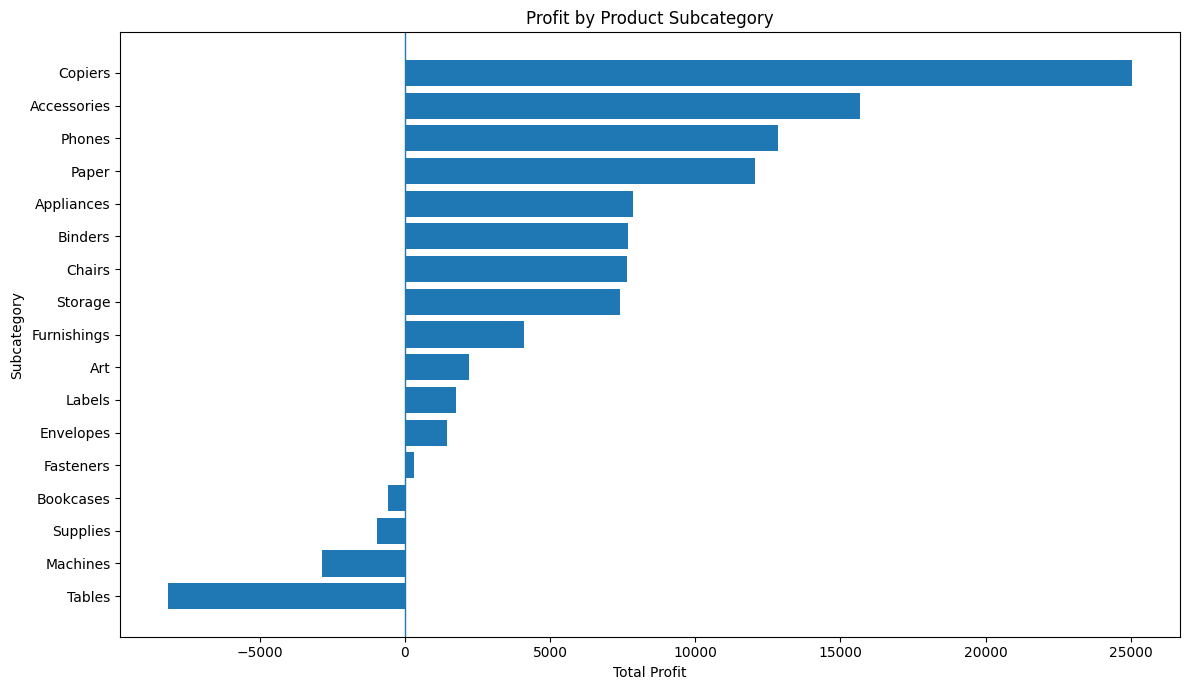

In [ ]:
plot_data = subcategory.sort_values("profit")
plt.figure(figsize=(12, 7))
plt.barh(plot_data["sub_category"], plot_data["profit"])
plt.axvline(0, linewidth=1)
plt.title("Profit by Product Subcategory")
plt.xlabel("Total Profit")
plt.ylabel("Subcategory")
plt.tight_layout()
plt.show()

In [ ]:
# Analyse discounts
year_df["discount_band"] = pd.cut(
    year_df["discount"],
    bins=[-0.001, 0, 0.10, 0.20, 0.30, 0.50, 1.00],
    labels=[
        "0%", "0–10%", "10–20%",
        "20–30%", "30–50%", "50%+"
    ],
    include_lowest=True
)

In [ ]:
discount_analysis = year_df.groupby(
    "discount_band", observed=False
).agg(
    sales=("sales", "sum"),
    profit=("profit", "sum"),
    orders=("order_id", "nunique"),
    avg_discount=("discount", "mean")
).reset_index()

In [ ]:
discount_analysis["profit_margin"] = (
    discount_analysis["profit"] /
    discount_analysis["sales"].replace(0, np.nan)
)

In [ ]:
print(discount_analysis.round(3).to_string(index=False))

discount_band      sales     profit  orders  avg_discount  profit_margin
           0% 348818.150 104157.712     901         0.000          0.299
        0–10%  18957.348   3300.593      24         0.100          0.174
       10–20% 258077.762  33550.864     818         0.199          0.130
       20–30%  31306.898  -3867.602      65         0.300         -0.124
       30–50%  54128.220 -16418.205      96         0.412         -0.303
         50%+  21926.877 -27284.093     228         0.724         -1.244


In [ ]:
# Segment performance
segment_analysis = year_df.groupby("segment").agg(
    sales=("sales", "sum"),
    profit=("profit", "sum"),
    orders=("order_id", "nunique"),
    units=("quantity", "sum")
).reset_index()

print("Segment analysis:")
print(segment_analysis.round(2).to_string(index=False))

Segment analysis:
    segment     sales   profit  orders  units
   Consumer 331904.70 45568.24     876   6282
  Corporate 241847.82 26782.36     493   3758
Home Office 159462.73 21088.67     318   2436


In [ ]:
# Regional performance
region_analysis = year_df.groupby("region").agg(
    sales=("sales", "sum"),
    profit=("profit", "sum"),
    orders=("order_id", "nunique")
).reset_index()

print("Regional analysis:")
print(region_analysis.round(2).to_string(index=False))

Regional analysis:
 region     sales   profit  orders
Central 147098.13  7550.84     406
   East 213082.90 33230.56     470
  South 122905.86  8848.91     273
   West 250128.37 43808.96     538


In [ ]:
# Find the beginnging to end change in sales
first_month = monthly.loc[1]
last_month = monthly.loc[12]

In [ ]:
sales_change = last_month["sales"] - first_month["sales"]

In [ ]:
sales_change_pct = (
    (last_month["sales"] / first_month["sales"]) - 1
) * 100 if first_month["sales"] != 0 else np.nan

In [ ]:
print(f"January sales: ${first_month['sales']:,.2f}")
print(f"December sales: ${last_month['sales']:,.2f}")
print(f"Absolute change: ${sales_change:,.2f}")
print(f"Percentage change: {sales_change_pct:.2f}%")
print(f"Annual sales: ${monthly['sales'].sum():,.2f}")
print(f"Annual profit: ${monthly['profit'].sum():,.2f}")

January sales: $43,971.37
December sales: $83,829.32
Absolute change: $39,857.94
Percentage change: 90.65%
Annual sales: $733,215.26
Annual profit: $93,439.27


In [ ]:
# Export the selected year for Power BI
year_df.to_csv("superstore_clean.csv", index=False)

In [ ]:
# Export the monthly summary for reference
monthly.reset_index().to_csv(
    "monthly_sales_summary.csv", index=False
)

In [ ]:
files.download("superstore_clean.csv")
files.download("monthly_sales_summary.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Load Database into SQLite Server

In [ ]:
# import sqlite
import sqlite3
import pandas as pd

In [ ]:
conn = sqlite3.connect("superstore.db")

In [ ]:
year_df.to_sql(
    "sales",
    conn,
    if_exists="replace",
    index=False
)

3312

In [ ]:
check = pd.read_sql_query(
    "SELECT * FROM sales LIMIT 5",
    conn
)
check

,row_id,order_id,order_date,ship_date,ship_mode,customer_id,customer_name,segment,country,city,...,product_id,category,sub_category,product_name,sales,quantity,discount,profit,year,discount_band
0,13,CA-2017-114412,2017-04-15 00:00:00,2017-04-20 00:00:00,Standard Class,AA-10480,Andrew Allen,Consumer,United States,Concord,...,OFF-PA-10002365,Office Supplies,Paper,Xerox 1967,15.552,3,0.2,5.4432,2017,10–20%
1,24,US-2017-156909,2017-07-16 00:00:00,2017-07-18 00:00:00,Second Class,SF-20065,Sandra Flanagan,Consumer,United States,Philadelphia,...,FUR-CH-10002774,Furniture,Chairs,"Global Deluxe Stacking Chair, Gray",71.372,2,0.3,-1.0196,2017,20–30%
2,35,CA-2017-107727,2017-10-19 00:00:00,2017-10-23 00:00:00,Second Class,MA-17560,Matt Abelman,Home Office,United States,Houston,...,OFF-PA-10000249,Office Supplies,Paper,Easy-staple paper,29.472,3,0.2,9.9468,2017,10–20%
3,42,CA-2017-120999,2017-09-10 00:00:00,2017-09-15 00:00:00,Standard Class,LC-16930,Linda Cazamias,Corporate,United States,Naperville,...,TEC-PH-10004093,Technology,Phones,Panasonic Kx-TS550,147.168,4,0.2,16.5564,2017,10–20%
4,44,CA-2017-139619,2017-09-19 00:00:00,2017-09-23 00:00:00,Standard Class,ES-14080,Erin Smith,Corporate,United States,Melbourne,...,OFF-ST-10003282,Office Supplies,Storage,"Advantus 10-Drawer Portable Organizer, Chrome ...",95.616,2,0.2,9.5616,2017,10–20%


# Create and Run SQL Queries to Answer Business Questions

In [ ]:
query = """
SELECT
    CAST(strftime('%m', order_date) AS INTEGER) AS month,
    ROUND(SUM(sales), 2) AS total_sales,
    ROUND(SUM(profit), 2) AS total_profit,
    ROUND(
        100.0 * SUM(profit) / NULLIF(SUM(sales), 0),
        2
    ) AS profit_margin_pct,
    COUNT(DISTINCT order_id) AS total_orders
FROM sales
GROUP BY strftime('%m', order_date)
ORDER BY month;
"""
monthly_sql = pd.read_sql_query(query, conn)
monthly_sql

,month,total_sales,total_profit,profit_margin_pct,total_orders
0,1,43971.37,7140.44,16.24,69
1,2,20301.13,1613.87,7.95,53
2,3,58872.35,14751.89,25.06,118
3,4,36521.54,933.29,2.56,116
4,5,44261.11,6342.58,14.33,118
5,6,52981.73,8223.34,15.52,133
6,7,45264.42,6952.62,15.36,111
7,8,63120.89,9040.96,14.32,111
8,9,87866.65,10991.56,12.51,226
9,10,77776.92,9275.28,11.93,147


In [ ]:
query = """
SELECT
    category,
    sub_category,
    ROUND(SUM(sales), 2) AS total_sales,
    ROUND(SUM(profit), 2) AS total_profit,
    ROUND(
        100.0 * SUM(profit) / NULLIF(SUM(sales), 0),
        2
    ) AS profit_margin_pct
FROM sales
GROUP BY category, sub_category
ORDER BY total_profit ASC;
"""
read_sql = pd.read_sql_query(query, conn)
read_sql

,category,sub_category,total_sales,total_profit,profit_margin_pct
0,Furniture,Tables,60893.54,-8140.69,-13.37
1,Technology,Machines,43544.68,-2869.22,-6.59
2,Office Supplies,Supplies,16049.41,-955.31,-5.95
3,Furniture,Bookcases,30024.28,-583.63,-1.94
4,Office Supplies,Fasteners,857.59,304.95,35.56
5,Office Supplies,Envelopes,3378.57,1441.76,42.67
6,Office Supplies,Labels,3861.22,1744.61,45.18
7,Office Supplies,Art,8863.07,2221.96,25.07
8,Furniture,Furnishings,28915.09,4099.16,14.18
9,Office Supplies,Storage,69677.62,7402.80,10.62


In [ ]:
query = """
SELECT
    CASE
        WHEN discount = 0 THEN '0%'
        WHEN discount <= 0.10 THEN '0-10%'
        WHEN discount <= 0.20 THEN '10-20%'
        WHEN discount <= 0.30 THEN '20-30%'
        ELSE 'Over 30%'
    END AS discount_band,
    COUNT(*) AS line_items,
    COUNT(DISTINCT order_id) AS orders,
    ROUND(SUM(sales), 2) AS total_sales,
    ROUND(SUM(profit), 2) AS total_profit,
    ROUND(
        100.0 * SUM(profit) / NULLIF(SUM(sales), 0),
        2
    ) AS profit_margin_pct
FROM sales
GROUP BY 1
ORDER BY MIN(discount);
"""
read_sql = pd.read_sql_query(query, conn)
read_sql

,discount_band,line_items,orders,total_sales,total_profit,profit_margin_pct
0,0%,1590,901,348818.15,104157.71,29.86
1,0-10%,28,24,18957.35,3300.59,17.41
2,10-20%,1239,818,258077.76,33550.86,13.00
3,20-30%,68,65,31306.90,-3867.60,-12.35
4,Over 30%,387,301,76055.10,-43702.30,-57.46


In [ ]:
query = """

SELECT
    region,
    ROUND(SUM(sales), 2) AS total_sales,
    ROUND(SUM(profit), 2) AS total_profit,
    COUNT(DISTINCT order_id) AS total_orders,
    ROUND(
        SUM(sales) / NULLIF(COUNT(DISTINCT order_id), 0),
        2
    ) AS revenue_per_order
FROM sales
GROUP BY region
ORDER BY total_profit ASC;
"""
read_sql = pd.read_sql_query(query, conn)
read_sql

,region,total_sales,total_profit,total_orders,revenue_per_order
0,Central,147098.13,7550.84,406,362.31
1,South,122905.86,8848.91,273,450.20
2,East,213082.90,33230.56,470,453.37
3,West,250128.37,43808.96,538,464.92


# Export Jupyter Notebook

